<a href="https://www.kaggle.com/code/najeebullah160/phase3-graphids-training?scriptVersionId=372278903" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Phase 3 — GraphIDS Model Training (E-GraphSAGE + Transformer MAE)

**Goal:** train the anomaly detector on benign edges only, evaluate on unseen val/test edges, measure generalization to unseen IPs, and narrate results with the Groq LLM (ground-truth numbers only).

**Needs:** GPU T4 x2 · Phase 2 output attached as Input · Runtime ≈ 30–60 min (early stopping usually ends it sooner).

In [1]:
# === CELL 1: ENVIRONMENT SETUP ===
import subprocess, sys, importlib

def ensure(pkg, pip_name=None):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_name or pkg], check=False)

ensure('pyarrow'); ensure('sklearn', 'scikit-learn'); ensure('joblib')

import os, json, random, glob, shutil, time
import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, confusion_matrix, precision_recall_curve)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU only')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if device.type == 'cuda': torch.cuda.manual_seed_all(SEED)

torch 2.11.0+cu130 | device: cuda:0 | Tesla T4


In [2]:
# === CELL 2: LOAD PHASE 2 ARTIFACTS (auto-locates the attached Phase 2 output) ===
import glob, os, shutil, json, numpy as np

if os.path.exists('artifacts/graph.npz'):
    GRAPH = 'artifacts/graph.npz'                       # already staged / local run
else:
    hits = glob.glob('/kaggle/input/**/artifacts/graph.npz', recursive=True)
    assert hits, ("Phase 2 output not attached! Add Input -> Your Work -> "
                  "'Phase2 Preprocessing Graph' (saved version with outputs), then re-run.")
    src_dir = os.path.dirname(hits[0])
    os.makedirs('artifacts', exist_ok=True)
    for f in glob.glob(os.path.join(src_dir, '*')):
        if os.path.basename(f) != 'graph.npz':          # copy everything EXCEPT the big file
            shutil.copy(f, os.path.join('artifacts', os.path.basename(f)))
            print('Copied:', os.path.basename(f))
    for md in glob.glob('/kaggle/input/**/phase2_preprocessing_report.md', recursive=True):
        if not os.path.exists(os.path.basename(md)):
            shutil.copy(md, os.path.basename(md)); print('Copied:', os.path.basename(md))
    GRAPH = hits[0]
print('graph.npz source:', GRAPH)

z = np.load(GRAPH)
edge_index  = z['edge_index']                       # (2, N) int64
edge_attr   = z['edge_attr'].astype(np.float32)     # (N, 45) scaled in Phase 2
edge_label  = z['edge_label']                       # (N,) int8: 0 benign, 1 attack
edge_attack = z['edge_attack']                      # (N,) int16 attack class code
train_mask, val_mask, test_mask = z['train_mask'], z['val_mask'], z['test_mask']
del z

cfg = json.load(open('artifacts/preprocessing_config.json'))
N_NODES, ATTACK_CLASSES = cfg['n_nodes'], cfg['attack_classes']
src, dst = edge_index[0], edge_index[1]

assert edge_attr.shape == (2350609, 45) and N_NODES == 44, 'Phase 2 artifacts changed?'
assert train_mask.sum() + val_mask.sum() + test_mask.sum() == len(edge_label)

CLIP = 10.0                                         # paper §4.2: clip scaled values to [-10, 10]
n_clipped = int((np.abs(edge_attr) > CLIP).sum())
edge_attr = np.clip(edge_attr, -CLIP, CLIP)

print(f"Graph loaded: {edge_attr.shape[0]:,} edges x {edge_attr.shape[1]} features | {N_NODES} nodes")
print(f"Clipped {n_clipped:,} extreme values to +/-{CLIP}")
print(f"Attack classes: {ATTACK_CLASSES}")

Copied: nodes.parquet
Copied: preprocessing_config.json
Copied: scaler.joblib
Copied: phase2_preprocessing_report.md
graph.npz source: /kaggle/input/notebooks/najeebullah160/phase2-preprocessing-graph/artifacts/graph.npz
Graph loaded: 2,350,609 edges x 45 features | 44 nodes
Clipped 57,995 extreme values to +/-10.0
Attack classes: ['Analysis', 'Backdoor', 'Benign', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Reconnaissance', 'Shellcode', 'Worms']


In [3]:
# === CELL 3: PARTITIONS, BENIGN-ONLY TRAIN SET, UNSEEN IPs ===
import collections

nodes = pd.read_parquet('artifacts/nodes.parquet')
name_col = 'ip' if 'ip' in nodes.columns else nodes.columns[0]
node_names = nodes[name_col].astype(str).tolist()
assert len(node_names) == N_NODES, f'nodes.parquet has {len(node_names)} rows, expected {N_NODES}'

def cname(c):
    """Tolerant attack-class name lookup (works for dict or list encodings)."""
    if isinstance(ATTACK_CLASSES, dict):
        return ATTACK_CLASSES.get(c, ATTACK_CLASSES.get(str(c), f'class {c}'))
    if isinstance(ATTACK_CLASSES, (list, tuple)) and 0 <= int(c) < len(ATTACK_CLASSES):
        return ATTACK_CLASSES[int(c)]
    return f'class {c}'

ben_train = train_mask & (edge_label == 0)
n_ben_train = int(ben_train.sum())

seen = np.zeros(N_NODES, dtype=bool)
seen[src[ben_train]] = True; seen[dst[ben_train]] = True
unseen = np.where(~seen)[0]
unseen_names = [node_names[i] for i in unseen]

print(f"Train {int(train_mask.sum()):,} edges -> benign used for training: {n_ben_train:,}")
print(f"Val   {int(val_mask.sum()):,} edges (attacks {int(edge_label[val_mask].sum()):,})")
print(f"Test  {int(test_mask.sum()):,} edges (attacks {int(edge_label[test_mask].sum()):,})")
print(f"Nodes with benign train edges: {int(seen.sum())}/{N_NODES} | Unseen IPs: {unseen_names}")

tc = collections.Counter(edge_attack[test_mask & (edge_label == 1)].tolist())
print('Test attack classes:', {cname(k): v for k, v in sorted(tc.items())})

Train 1,131,909 edges -> benign used for training: 1,114,449
Val   182,805 edges (attacks 17,568)
Test  1,035,895 edges (attacks 92,651)
Nodes with benign train edges: 40/44 | Unseen IPs: ['10.40.182.255', '10.40.182.6', '10.40.85.10', '192.168.241.50']
Test attack classes: {'Analysis': 712, 'Backdoor': 1501, 'DoS': 4619, 'Exploits': 32493, 'Fuzzers': 24304, 'Generic': 14458, 'Reconnaissance': 12845, 'Shellcode': 1600, 'Worms': 119}


# Model — E-GraphSAGE (1-hop, node dim 48) + Transformer MAE (1 layer, d_model 48, 4 heads, window 512, mask 0.15)

Faithful to the paper (Lo et al. 2022, Table 14): 1-hop mean aggregation, CONCAT flow embedding, symmetric binary attention mask during training, unmasked inference. The smoke test regression-tests every failure mode hit so far: GPU device placement, remainder windows (length ≠ 512), and backward pass.

In [4]:
# === CELL 4: MODEL — E-GRAPHSAGE + TRANSFORMER MAE (all fixes baked in) ===
import torch, torch.nn as nn, torch.nn.functional as F

CONFIG = dict(
    SEED=42,
    # --- E-GraphSAGE (paper Table 14: edim_out=96 = 2x48 CONCAT, nhops=1, dropout 0.6) ---
    GNN_NODE_DIM=48, GNN_DROPOUT=0.6,
    # --- Transformer MAE (paper: 1 layer, 4 heads, d_model 48, window 512, mask 0.15, dropout 0) ---
    D_MODEL=48, NHEAD=4, N_LAYERS=1, FF_MULT=4,
    WINDOW=512, MASK_RATIO=0.15, AE_DROPOUT=0.0,
    # --- Training (paper: AdamW, lr 1e-4, gnn wd 0.6, ae wd 0.04, patience 20) ---
    LR=1e-4, WD_GNN=0.6, WD_AE=0.04,
    STEP_EDGES=32768, MAX_EPOCHS=100, PATIENCE=20,
)

class EGraphSAGE1Hop(nn.Module):
    """1-hop E-GraphSAGE, mean aggregation (Lo et al. 2022, Alg. 1).
    h_v = ReLU(W [ones ; ctx_v]);  z_uv = [h_src ; e_uv ; h_dst]  (decision T4)."""
    def __init__(self, n_feat, node_dim, dropout):
        super().__init__()
        self.register_buffer('ones', torch.ones(n_feat))
        self.lin = nn.Linear(2 * n_feat, node_dim)
        self.dropout = dropout
        self.flow_dim = 2 * node_dim + n_feat
    def forward(self, e, ctx_s, ctx_d):
        o = self.ones.expand(e.size(0), -1)
        h_s = F.relu(self.lin(torch.cat([o, ctx_s], dim=-1)))
        h_d = F.relu(self.lin(torch.cat([o, ctx_d], dim=-1)))
        z = torch.cat([h_s, e, h_d], dim=-1)
        return F.dropout(z, p=self.dropout, training=self.training)

class TransformerMAE(nn.Module):
    """Encoder-decoder Transformer. Training: SYMMETRIC BINARY mask (random pairs blocked
    both ways, ratio 0.15, diagonal visible); inference: unmasked (paper §3.3).
    The mask is built for the ACTUAL sequence length w (any w) — this is what
    crashed Cell 5 on remainder windows (512 mask vs 337 sequence)."""
    def __init__(self, flow_dim, d_model, nhead, n_layers, ff_mult, window, mask_ratio, dropout):
        super().__init__()
        self.in_proj = nn.Linear(flow_dim, d_model)
        self.encoder = nn.TransformerEncoder(
            nn.TransformerEncoderLayer(d_model, nhead, dim_feedforward=d_model*ff_mult,
                                       dropout=dropout, batch_first=True),
            n_layers, enable_nested_tensor=False)
        self.decoder = nn.TransformerDecoder(
            nn.TransformerDecoderLayer(d_model, nhead, dim_feedforward=d_model*ff_mult,
                                       dropout=dropout, batch_first=True), n_layers)
        self.out_proj = nn.Linear(d_model, flow_dim)
        self.window, self.mask_ratio = window, mask_ratio
    def _symmetric_mask(self, w, device):
        R = torch.rand(w, w, device=device)
        iu = torch.triu_indices(w, w, offset=1).to(device)   # FIX: indices on the mask's device
        block = R[iu[0], iu[1]] < self.mask_ratio
        m = torch.zeros(w, w, dtype=torch.bool, device=device)
        m[iu[0][block], iu[1][block]] = True
        m[iu[1][block], iu[0][block]] = True                 # symmetric: block both directions
        return m
    def forward(self, z):                                    # z: (B, w, flow_dim), ANY w
        h = self.in_proj(z)
        if self.training and self.mask_ratio > 0:
            m = self._symmetric_mask(h.size(1), h.device)    # FIX: w = actual length
            mem = self.encoder(h, mask=m)
            rec = self.decoder(h, mem, tgt_mask=m)
        else:
            mem = self.encoder(h)
            rec = self.decoder(h, mem)
        return self.out_proj(rec)

class GraphIDS(nn.Module):
    def __init__(self, n_feat, c):
        super().__init__()
        self.gnn = EGraphSAGE1Hop(n_feat, c['GNN_NODE_DIM'], c['GNN_DROPOUT'])
        self.ae  = TransformerMAE(self.gnn.flow_dim, c['D_MODEL'], c['NHEAD'], c['N_LAYERS'],
                                  c['FF_MULT'], c['WINDOW'], c['MASK_RATIO'], c['AE_DROPOUT'])
    def forward(self, e, ctx_s, ctx_d):
        z = self.gnn(e, ctx_s, ctx_d)
        n, W = z.size(0), self.ae.window
        if n % W == 0:
            zh = self.ae(z.view(-1, W, self.gnn.flow_dim))
        else:
            zh = torch.cat([self.ae(z[i:i+W].unsqueeze(0)).squeeze(0) for i in range(0, n, W)])
        return zh.reshape(z.shape), z                # FIX: flatten back to (n, flow_dim)

model = GraphIDS(45, CONFIG).to(device)
n_gnn = sum(p.numel() for p in model.gnn.parameters())
n_ae  = sum(p.numel() for p in model.ae.parameters())
print(f"Parameters: GNN {n_gnn:,} + Transformer MAE {n_ae:,} = {n_gnn+n_ae:,} total (paper: 0.874M)")

# --- smoke test: REGRESSION TESTS for every bug hit so far ---
model.train()
e  = torch.randn(CONFIG['STEP_EDGES'], 45, device=device)
cs = torch.randn(CONFIG['STEP_EDGES'], 45, device=device)
cd = torch.randn(CONFIG['STEP_EDGES'], 45, device=device)
zh, z = model(e, cs, cd)                                     # full 512-window batch
assert zh.shape == z.shape and torch.isfinite(zh).all() and torch.isfinite(z).all()
F.mse_loss(zh, z).backward()                                 # backward through GNN + AE
zr  = model.gnn(e[:337], cs[:337], cd[:337])                 # REMAINDER path, TRAIN mode (w=337)
zhr = model.ae(zr.unsqueeze(0)).squeeze(0)
assert zhr.shape == zr.shape and torch.isfinite(zhr).all()
model.eval()
with torch.no_grad():
    zr2  = model.gnn(e[:1000], cs[:1000], cd[:1000])         # remainder path, EVAL mode
    zhr2 = model.ae(zr2.unsqueeze(0)).squeeze(0)
assert zhr2.shape == zr2.shape and torch.isfinite(zhr2).all()
print(f"Smoke test ✔ — flow_dim {model.gnn.flow_dim}, masked/unmasked/remainder paths all OK")

Parameters: GNN 4,368 + Transformer MAE 79,773 = 84,141 total (paper: 0.874M)
Smoke test ✔ — flow_dim 141, masked/unmasked/remainder paths all OK


# Training & Evaluation

**Training:** joint GNN+MAE on benign edges only (decision T10, paper Eq. 2). Node profiles = mean of benign-train edge features per node (leak-free 1-hop context, T3). Early stopping on val PR-AUC, patience 20. Lower **PATIENCE** in CONFIG if you need to save GPU time.

**Evaluation:** threshold = p99 of benign validation errors → test metrics → per-attack-class recall → unseen-IP generalization → figures → Groq narration → artifacts + gate.

In [5]:
# === CELL 5: TRAINING — JOINT GNN+MAE ON BENIGN EDGES (T10, Eq. 2), EARLY STOP ===
torch.manual_seed(CONFIG['SEED'])

# --- tensors on device ---
edge_attr_t = torch.from_numpy(edge_attr).to(device)
src_t = torch.from_numpy(src.astype(np.int64)).to(device)
dst_t = torch.from_numpy(dst.astype(np.int64)).to(device)

# --- node behavioral profiles from BENIGN TRAIN edges only (T3, leak-free) ---
ben_train_idx = np.where(train_mask & (edge_label == 0))[0]
bi   = torch.from_numpy(ben_train_idx).to(device)
prof = torch.zeros(N_NODES, 45, device=device)
cnt  = torch.zeros(N_NODES, device=device)
prof.index_add_(0, src_t[bi], edge_attr_t[bi]); cnt.index_add_(0, src_t[bi], torch.ones(len(bi), device=device))
prof.index_add_(0, dst_t[bi], edge_attr_t[bi]); cnt.index_add_(0, dst_t[bi], torch.ones(len(bi), device=device))
ctx = prof / cnt.clamp(min=1.0).unsqueeze(1)      # unseen nodes -> zero profile
del prof
print(f"Node profiles from benign train: {int((cnt>0).sum())}/{N_NODES} nodes "
      f"| {int((cnt==0).sum())} unseen -> zero context")

W = CONFIG['WINDOW']

def gnn_z(idx):
    return model.gnn(edge_attr_t[idx], ctx[src_t[idx]], ctx[dst_t[idx]])

def forward_windows(z, win_batch=64):
    """Reconstruct flat (n, flow_dim) in windows of W; handles ANY remainder length."""
    n = z.size(0); outs = []
    for st in range(0, n, win_batch * W):
        zb = z[st : st + win_batch * W]
        nw = zb.size(0) // W
        if nw:
            outs.append(model.ae(zb[:nw*W].view(nw, W, -1)).reshape(nw*W, -1))
        if zb.size(0) % W:
            tail = zb[nw*W:]
            outs.append(model.ae(tail.unsqueeze(0)).squeeze(0))
    return torch.cat(outs) if outs else z

@torch.no_grad()
def score_partition(mask, win_batch=64):
    """Per-edge reconstruction error (sum over dims), chunked to stay in T4 memory."""
    was_training = model.training; model.eval()
    idx = torch.from_numpy(np.where(mask)[0]).to(device)
    z = gnn_z(idx); errs = []
    for st in range(0, z.size(0), win_batch * W):
        zb = z[st : st + win_batch * W]
        nw = zb.size(0) // W
        if nw:
            zh = model.ae(zb[:nw*W].view(nw, W, -1)).reshape(nw*W, -1)
            errs.append(((zh - zb[:nw*W]) ** 2).sum(-1))
        if zb.size(0) % W:
            tail = zb[nw*W:]
            zh = model.ae(tail.unsqueeze(0)).squeeze(0)
            errs.append(((zh - tail) ** 2).sum(-1))
    if was_training: model.train()
    return torch.cat(errs) if errs else torch.zeros(0, device=device)

val_y_np = edge_label[val_mask]
def val_metrics():
    e = score_partition(val_mask).cpu().numpy()
    return average_precision_score(val_y_np, e), float(e.mean())

# --- optimizer: separate weight decay for GNN vs AE (paper) ---
opt = torch.optim.AdamW([
    {'params': model.gnn.parameters(), 'weight_decay': CONFIG['WD_GNN']},
    {'params': model.ae.parameters(),  'weight_decay': CONFIG['WD_AE']},
], lr=CONFIG['LR'])

ben_t = torch.from_numpy(ben_train_idx).to(device)
n_train = ben_t.numel()
steps_per_epoch = (n_train + CONFIG['STEP_EDGES'] - 1) // CONFIG['STEP_EDGES']
print(f"Training on {n_train:,} benign edges | {steps_per_epoch} steps/epoch x {CONFIG['STEP_EDGES']:,} edges")

best_ap, best_state, bad, history = -1.0, None, 0, []
t0 = time.time(); model.train()
for epoch in range(1, CONFIG['MAX_EPOCHS'] + 1):
    perm = ben_t[torch.randperm(n_train, device=device)]
    run_loss = 0.0
    for st in range(0, n_train, CONFIG['STEP_EDGES']):
        idx = perm[st : st + CONFIG['STEP_EDGES']]
        z = gnn_z(idx)                            # gradient flows through GNN (T10: joint)
        zh = forward_windows(z)
        loss = F.mse_loss(zh, z)                  # paper Eq. 2: MSE in GNN embedding space
        opt.zero_grad(); loss.backward(); opt.step()
        run_loss += loss.item()
    ap, vmean = val_metrics()
    history.append((epoch, run_loss / steps_per_epoch, ap))
    star = ''
    if ap > best_ap:
        best_ap, bad = ap, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        star = '  <- best'
    else:
        bad += 1
    print(f"Epoch {epoch:3d} | train MSE {run_loss/steps_per_epoch:.4f} | "
          f"val PR-AUC {ap:.4f} | val err {vmean:.1f}{star}", flush=True)
    if bad >= CONFIG['PATIENCE']:
        print(f"Early stop: no val PR-AUC improvement for {CONFIG['PATIENCE']} epochs."); break

print(f"Done in {(time.time()-t0)/60:.1f} min | best val PR-AUC {best_ap:.4f}")
model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
model.eval()

Node profiles from benign train: 40/44 nodes | 4 unseen -> zero context
Training on 1,114,449 benign edges | 35 steps/epoch x 32,768 edges
Epoch   1 | train MSE 0.8534 | val PR-AUC 0.5649 | val err 76.7  <- best
Epoch   2 | train MSE 0.6867 | val PR-AUC 0.5876 | val err 58.3  <- best
Epoch   3 | train MSE 0.5729 | val PR-AUC 0.5961 | val err 49.1  <- best
Epoch   4 | train MSE 0.5144 | val PR-AUC 0.6068 | val err 45.1  <- best
Epoch   5 | train MSE 0.4797 | val PR-AUC 0.6211 | val err 42.5  <- best
Epoch   6 | train MSE 0.4537 | val PR-AUC 0.6474 | val err 40.4  <- best
Epoch   7 | train MSE 0.4237 | val PR-AUC 0.6622 | val err 38.8  <- best
Epoch   8 | train MSE 0.4054 | val PR-AUC 0.6721 | val err 37.4  <- best
Epoch   9 | train MSE 0.3859 | val PR-AUC 0.6834 | val err 36.3  <- best
Epoch  10 | train MSE 0.3712 | val PR-AUC 0.6922 | val err 35.2  <- best
Epoch  11 | train MSE 0.3559 | val PR-AUC 0.7008 | val err 34.3  <- best
Epoch  12 | train MSE 0.3378 | val PR-AUC 0.7100 | val err

GraphIDS(
  (gnn): EGraphSAGE1Hop(
    (lin): Linear(in_features=90, out_features=48, bias=True)
  )
  (ae): TransformerMAE(
    (in_proj): Linear(in_features=141, out_features=48, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0): TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=48, out_features=48, bias=True)
          )
          (linear1): Linear(in_features=48, out_features=192, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=192, out_features=48, bias=True)
          (norm1): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((48,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (decoder): TransformerDecoder(
      (layers): ModuleList(
        (0): Transfo

In [6]:
# === CELL 6: THRESHOLD SELECTION (p99 of val benign errors) ===
val_err = score_partition(val_mask).cpu().numpy()
val_y   = edge_label[val_mask]
ben_err, atk_err = val_err[val_y == 0], val_err[val_y == 1]
print(f"Val errors — benign mean {ben_err.mean():.1f} (p99 {np.percentile(ben_err, 99):.1f}) "
      f"| attack mean {atk_err.mean():.1f}")

print(f"{'pct':>6} {'threshold':>12} {'precision':>10} {'recall':>8} {'F1':>8}")
for p in [95, 99, 99.5, 99.9]:
    th = np.percentile(ben_err, p)
    pred = (val_err > th).astype(int)
    print(f"{p:>6} {th:>12.1f} {precision_score(val_y, pred, zero_division=0):>10.3f} "
          f"{recall_score(val_y, pred):>8.3f} {f1_score(val_y, pred):>8.3f}")

THRESHOLD = float(np.percentile(ben_err, 99))
np.save('artifacts/threshold.npy', np.array([THRESHOLD]))
print(f"\nSelected threshold (p99 of val benign errors): {THRESHOLD:.1f}")

Val errors — benign mean 10.9 (p99 126.7) | attack mean 186.3
   pct    threshold  precision   recall       F1
    95         15.7      0.659    0.910    0.765
    99        126.7      0.890    0.760    0.820
  99.5        206.9      0.923    0.567    0.703
  99.9        404.6      0.503    0.010    0.019

Selected threshold (p99 of val benign errors): 126.7


In [7]:
# === CELL 7: TEST EVALUATION ===
test_err  = score_partition(test_mask).cpu().numpy()
test_y    = edge_label[test_mask]
test_pred = (test_err > THRESHOLD).astype(int)

pr_auc = average_precision_score(test_y, test_err)
roc    = roc_auc_score(test_y, test_err) if test_y.min() != test_y.max() else float('nan')
P, R = precision_score(test_y, test_pred, zero_division=0), recall_score(test_y, test_pred)
F1s  = f1_score(test_y, test_pred)
tn, fp, fn, tp = confusion_matrix(test_y, test_pred).ravel()

print(f"TEST (n={len(test_y):,} | attacks {int(test_y.sum()):,})")
print(f"PR-AUC {pr_auc:.4f} | ROC-AUC {roc:.4f}")
print(f"Precision {P:.4f} | Recall {R:.4f} | F1 {F1s:.4f}")
print(f"TP {tp:,} | FP {fp:,} | FN {fn:,} | TN {tn:,}")

RESULTS = dict(pr_auc=float(pr_auc), roc_auc=float(roc), precision=float(P), recall=float(R),
               f1=float(F1s), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn),
               threshold=THRESHOLD, n_test=int(len(test_y)), n_test_attacks=int(test_y.sum()))

TEST (n=1,035,895 | attacks 92,651)
PR-AUC 0.8074 | ROC-AUC 0.9813
Precision 0.8977 | Recall 0.7580 | F1 0.8220
TP 70,233 | FP 8,000 | FN 22,418 | TN 935,244


In [8]:
# === CELL 8: PER-ATTACK-CLASS DETECTION (aligned to the test partition) ===
test_codes = edge_attack[test_mask]
test_atk   = test_y == 1
rows = []
for c in np.unique(test_codes[test_atk]):
    m = test_atk & (test_codes == c)
    n = int(m.sum()); det = int((test_err[m] > THRESHOLD).sum())
    rows.append((cname(c), n, det, det / n if n else 0.0))
rows.sort(key=lambda r: -r[1])
print(f"{'attack class':<30}{'edges':>9}{'detected':>10}{'recall':>9}")
for name, n, det, rc in rows:
    print(f"{name:<30}{n:>9,}{det:>10,}{rc:>9.1%}")

attack class                      edges  detected   recall
Exploits                         32,493    15,565    47.9%
Fuzzers                          24,304    23,877    98.2%
Generic                          14,458    13,085    90.5%
Reconnaissance                   12,845    11,757    91.5%
DoS                               4,619     3,193    69.1%
Shellcode                         1,600     1,435    89.7%
Backdoor                          1,501     1,195    79.6%
Analysis                            712        10     1.4%
Worms                               119       116    97.5%


In [9]:
# === CELL 9: UNSEEN IP GENERALIZATION ===
unseen_edge = np.isin(src, unseen) | np.isin(dst, unseen)
um = unseen_edge & test_mask
n_um = int(um.sum())
UNSEEN = dict(n_edges=n_um, n_attacks=0, recall=None)
if n_um:
    uy   = edge_label[um]
    uerr = score_partition(um).cpu().numpy()
    upred = (uerr > THRESHOLD).astype(int)
    UNSEEN['n_attacks'] = int(uy.sum())
    print(f"Test edges touching unseen IPs: {n_um:,} (attacks {int(uy.sum()):,})")
    if uy.min() != uy.max():
        UNSEEN['recall'] = float(recall_score(uy, upred))
        print(f"Unseen-IP recall {UNSEEN['recall']:.4f} "
              f"| PR-AUC {average_precision_score(uy, uerr):.4f}")
    else:
        print(f"Flagged {int(upred.sum())}/{n_um} edges (single-class slice)")
else:
    print('No unseen-IP edges in the test partition.')

Test edges touching unseen IPs: 445 (attacks 0)
Flagged 204/445 edges (single-class slice)


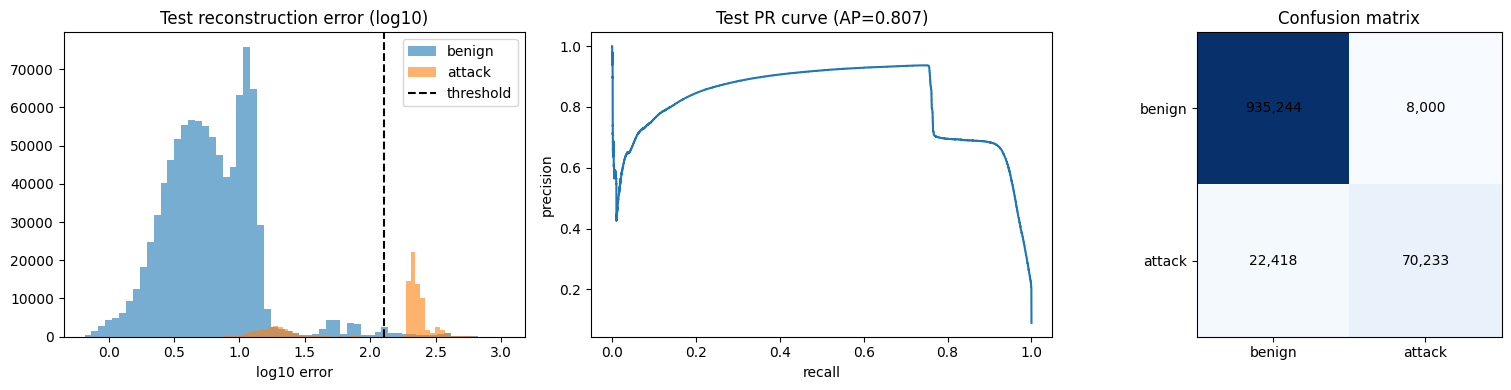

In [10]:
# === CELL 10: FIGURES ===
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(np.log10(test_err[test_y == 0] + 1e-3), bins=60, alpha=0.6, label='benign')
ax[0].hist(np.log10(test_err[test_y == 1] + 1e-3), bins=60, alpha=0.6, label='attack')
ax[0].axvline(np.log10(THRESHOLD + 1e-3), color='k', ls='--', label='threshold')
ax[0].set(title='Test reconstruction error (log10)', xlabel='log10 error'); ax[0].legend()
prec, rec, _ = precision_recall_curve(test_y, test_err)
ax[1].plot(rec, prec)
ax[1].set(title=f'Test PR curve (AP={pr_auc:.3f})', xlabel='recall', ylabel='precision')
cm = confusion_matrix(test_y, test_pred)
ax[2].imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm): ax[2].text(j, i, f'{v:,}', ha='center', va='center')
ax[2].set(title='Confusion matrix', xticks=[0, 1], xticklabels=['benign', 'attack'],
          yticks=[0, 1], yticklabels=['benign', 'attack'])
plt.tight_layout(); plt.savefig('artifacts/phase3_figures.png', dpi=120); plt.show()

In [11]:
# === CELL 11: LLM NARRATION (Groq) — GROUND-TRUTH NUMBERS ONLY ===
import requests, json as _json

def get_groq_key():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('GROQ_API_KEY')
    except Exception:
        return os.environ.get('GROQ_API_KEY')

facts = dict(
    model='E-GraphSAGE 1-hop (node dim 48) + 1-layer Transformer MAE (d_model 48, 4 heads, window 512, mask 0.15)',
    parameters=n_gnn + n_ae,
    trained_on=f'{n_train:,} benign train edges (benign-only, joint GNN+MAE)',
    threshold_rule='99th percentile of benign validation reconstruction error',
    threshold=round(float(THRESHOLD), 2),
    test_results={k: (round(v, 4) if isinstance(v, float) else v) for k, v in RESULTS.items()},
    unseen_ips=unseen_names, unseen_ip_results=UNSEEN,
)
prompt = ("You are narrating Phase 3 (GraphIDS training) of an explainable NIDS project for a report. "
          "Write 6-8 sentences, technical but readable. STRICT RULE: use ONLY the numbers in the JSON "
          "below — do not invent, round, or embellish any figure. Omit anything not provided.\n\n"
          + _json.dumps(facts, indent=1))

key, narration = get_groq_key(), None
if key:
    try:
        r = requests.post('https://api.groq.com/openai/v1/chat/completions',
                          headers={'Authorization': f'Bearer {key}'},
                          json={'model': 'openai/gpt-oss-120b',
                                'messages': [{'role': 'user', 'content': prompt}],
                                'temperature': 0.2}, timeout=60)
        r.raise_for_status()
        narration = r.json()['choices'][0]['message']['content']
    except Exception as ex:
        print('Groq call failed:', ex)
if narration:
    print(narration)
    open('artifacts/phase3_narration.md', 'w').write(narration)
else:
    print('LLM narration skipped — verified facts for the report:\n', _json.dumps(facts, indent=1))

Phase 3 employed the E‑GraphSAGE 1‑hop (node dim 48) combined with a 1‑layer Transformer MAE (d_model 48, 4 heads, window 512, mask 0.15), a lightweight architecture with 84141 trainable parameters. The model was trained exclusively on 1,114,449 benign train edges in a joint GNN + MAE setting. Anomaly detection used the 99th percentile of benign validation reconstruction error as the decision rule, yielding a threshold of 126.72 (the test‑time threshold was 126.7221). Evaluation was performed on a test set of 1035895 samples, of which 92651 were attacks. The resulting scores were PR AUC 0.8074, ROC AUC 0.9813, precision 0.8977, recall 0.758, and F1 0.822. The confusion matrix recorded 70233 true positives, 8000 false positives, 22418 false negatives, and 935244 true negatives. When the trained detector was applied to four previously unseen IPs—10.40.182.255, 10.40.182.6, 10.40.85.10, and 192.168.241.50—it processed 445 edges, found 0 attacks, and therefore a recall value is not applica

In [12]:
# === CELL 12: SAVE ARTIFACTS + PHASE 3 GATE ===
import datetime

torch.save({'state_dict': {k: v.cpu() for k, v in model.state_dict().items()},
            'config': CONFIG, 'threshold': THRESHOLD, 'results': RESULTS,
            'history': history}, 'artifacts/graphids_model.pt')

summary = dict(
    phase='Phase 3 — GraphIDS training & evaluation',
    finished=datetime.datetime.now().isoformat(timespec='seconds'),
    model='E-GraphSAGE (1-hop, 48) + Transformer MAE (1 layer, d_model 48, 4 heads, window 512, mask 0.15)',
    parameters=n_gnn + n_ae, train_benign_edges=int(n_train),
    threshold=THRESHOLD, threshold_rule='p99 of val benign errors',
    best_val_pr_auc=round(float(best_ap), 4), test=RESULTS,
    unseen_ips=UNSEEN, epochs_run=int(history[-1][0]),
)
json.dump(summary, open('artifacts/phase3_summary.json', 'w'), indent=2, default=str)

print('Saved: graphids_model.pt, phase3_summary.json, threshold.npy, phase3_figures.png')
ap = RESULTS['pr_auc']
gate = 'PASS ✔' if ap >= 0.90 else 'WARN ⚠️ — PR-AUC below 0.90, check the training log'
print(f"\nPHASE 3 GATE: {gate}")
print(f"Test PR-AUC {ap:.4f} | Recall {RESULTS['recall']:.4f} | F1 {RESULTS['f1']:.4f} "
      f"| threshold {THRESHOLD:.1f}")
print('Next: save version with outputs, commit to GitHub, then Phase 4 (explainability).')

Saved: graphids_model.pt, phase3_summary.json, threshold.npy, phase3_figures.png

PHASE 3 GATE: WARN ⚠️ — PR-AUC below 0.90, check the training log
Test PR-AUC 0.8074 | Recall 0.7580 | F1 0.8220 | threshold 126.7
Next: save version with outputs, commit to GitHub, then Phase 4 (explainability).
